# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  


**Team: Kiersten Bruns, Ciara Graves, Olympia Sauerwein, and Camden Lanin**

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [19]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

folder_path = '/content/drive/MyDrive/DS2002: Midterm Notebooks'
cleaned_folder = os.path.join(folder_path, 'cleaned_data')
weather_folder = os.path.join(folder_path, 'weather_data')

transactions_clean = pd.read_csv(
    os.path.join(cleaned_folder, 'transactions_clean.csv'),
    parse_dates=['timestamp']
)

product_catalog_clean = pd.read_csv(
    os.path.join(cleaned_folder, 'product_catalog_clean.csv')
)

weather_clean = pd.read_csv(
    os.path.join(weather_folder, 'weather_clean.csv'),
    parse_dates=['date']
)

print("Transactions:", transactions_clean.shape)
print("Catalog:", product_catalog_clean.shape)
print("Weather:", weather_clean.shape)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Transactions: (25532, 9)
Catalog: (45, 7)
Weather: (360, 8)


In [20]:
# check
#print(q1.columns.tolist())

In [21]:
# TODO: the numbers
# We need baseline, surge

# Q1: Demand surge analysis

q1 = transactions_clean.copy()

q1['date'] = pd.to_datetime(q1['timestamp']).dt.normalize()

baseline_start = pd.Timestamp('2024-09-12')
baseline_end = pd.Timestamp('2024-09-18')

surge_start = pd.Timestamp('2024-09-19')
surge_end = pd.Timestamp('2024-09-25')

baseline = q1[
    q1['date'].between(baseline_start, baseline_end)
]

surge = q1[
    q1['date'].between(surge_start, surge_end)
]

# Average daily net units by category
baseline_avg = (
    baseline.groupby('category')['quantity'].sum() / 7
)

surge_avg = (
    surge.groupby('category')['quantity'].sum() / 7
)

q1_results = pd.DataFrame({
    'baseline_avg': baseline_avg,
    'surge_avg': surge_avg
}).fillna(0)

q1_results['multiple'] = (
    q1_results['surge_avg'] /
    q1_results['baseline_avg'].replace(0, np.nan)
)

q1_results['percent_change'] = (
    (q1_results['multiple'] - 1) * 100
)

q1_results = q1_results.sort_values(
    'multiple', ascending=False
)

display(q1_results)

top_category = q1_results['multiple'].idxmax()
top_multiple = q1_results.loc[top_category, 'multiple']

print("Largest surge category:", top_category)
print("Surge multiple:", round(top_multiple, 2))



,baseline_avg,surge_avg,multiple,percent_change
category,,,,
Breakfast,110.142857,375.714286,3.411154,241.115435
Emergency,421.571429,1002.285714,2.377499,137.749915
Electronics,77.428571,175.285714,2.263838,126.383764
Entertainment,109.571429,227.000000,2.071708,107.170795
Alcohol,67.000000,138.285714,2.063966,106.396588
Health,47.571429,94.142857,1.978979,97.897898
Household,97.857143,175.857143,1.797080,79.708029
Grocery,193.000000,305.285714,1.581791,58.179127
Baby,90.428571,132.571429,1.466035,46.603476


Largest surge category: Breakfast
Surge multiple: 3.41


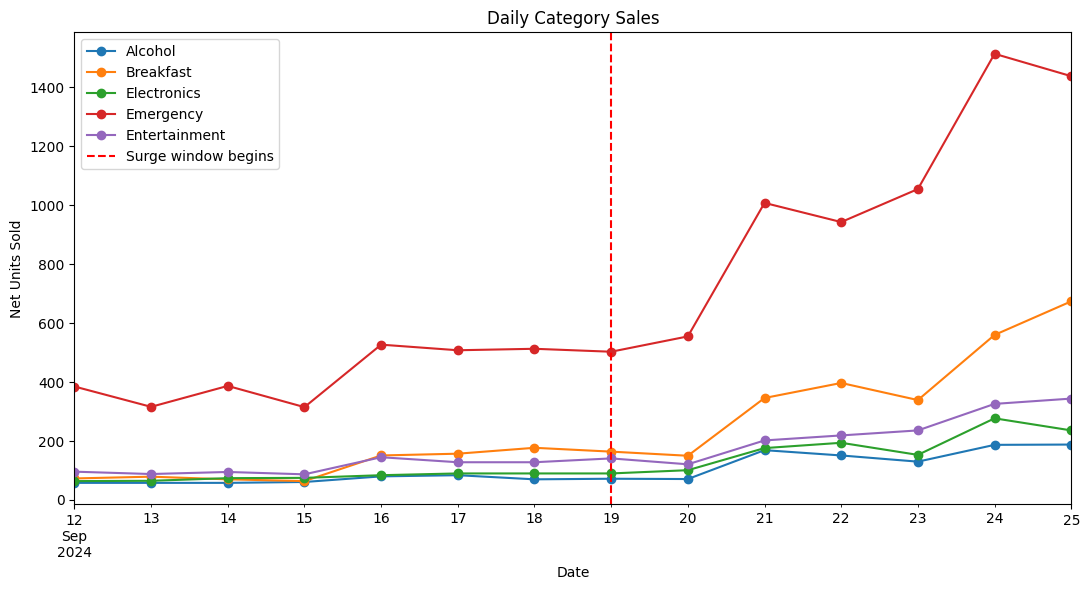

In [22]:
# TODO: the chart
# Top 5 category plot
top5 = q1_results.head(5).index

q1_daily = (
    q1[
        q1['category'].isin(top5) &
        q1['date'].between(baseline_start, surge_end)
    ]
    .groupby(['date', 'category'])['quantity']
    .sum()
    .unstack(fill_value=0)
)

ax = q1_daily.plot(figsize=(11, 6), marker='o')

ax.axvline(
    surge_start,
    color='red',
    linestyle='--',
    label='Surge window begins'
)

ax.set_title(
    'Daily Category Sales'
)
ax.set_xlabel('Date')
ax.set_ylabel('Net Units Sold')

plt.legend()
plt.tight_layout()
plt.show()



**Q1 answer, in one sentence a manager could read:** We need to complete our surge calculations, so the data here is taken from dates in the cleaned data; we can note an increase in emergency and breakfast items as the storm approaches

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [23]:
# TODO

# Q2: SKU consolidation

pop_tart_catalog = product_catalog_clean[
    product_catalog_clean['product_name']
    .astype(str)
    .str.contains(r'pop[\s-]*tarts?', case=False, na=False)
].copy()

pop_tart_skus = pop_tart_catalog['sku'].unique()

pop_tart_transactions = transactions_clean[
    transactions_clean['sku'].isin(pop_tart_skus)
].copy()

pop_tart_transactions = pop_tart_transactions.dropna(
    subset=['timestamp']
)

pop_tart_transactions['date'] = (
    pd.to_datetime(pop_tart_transactions['timestamp'])
    .dt.normalize()
)

# Before consolidation
fragmented_daily = (
    pop_tart_transactions
    .groupby(['date', 'sku'])['quantity']
    .sum()
    .reset_index()
)

# After consolidation
consolidated_daily = (
    pop_tart_transactions
    .groupby('date')['quantity']
    .sum()
    .reset_index(name='total_pop_tart_units')
)

sku_totals = (
    fragmented_daily.groupby('sku')['quantity']
    .sum()
    .sort_values(ascending=False)
)

original_skus = len(sku_totals)
canonical_products = 1

total_units = consolidated_daily['total_pop_tart_units'].sum()
avg_daily = consolidated_daily['total_pop_tart_units'].mean()

# Verify units are preserved
assert sku_totals.sum() == total_units

print("Original SKUs:", original_skus)
print("Canonical products:", canonical_products)
print("Total units:", total_units)
print("Average daily units:", round(avg_daily, 2))
print("Top category:", top_category)
print("Daily unit sales increase:", round(top_multiple,2))

display(sku_totals)


Original SKUs: 4
Canonical products: 1
Total units: 4985
Average daily units: 166.17
Top category: Breakfast
Daily unit sales increase: 3.41


,quantity
sku,
PT-12,1328
POPTART-STRAW,1233
PT_STRAWBERRY,1222
SKU#459812,1202


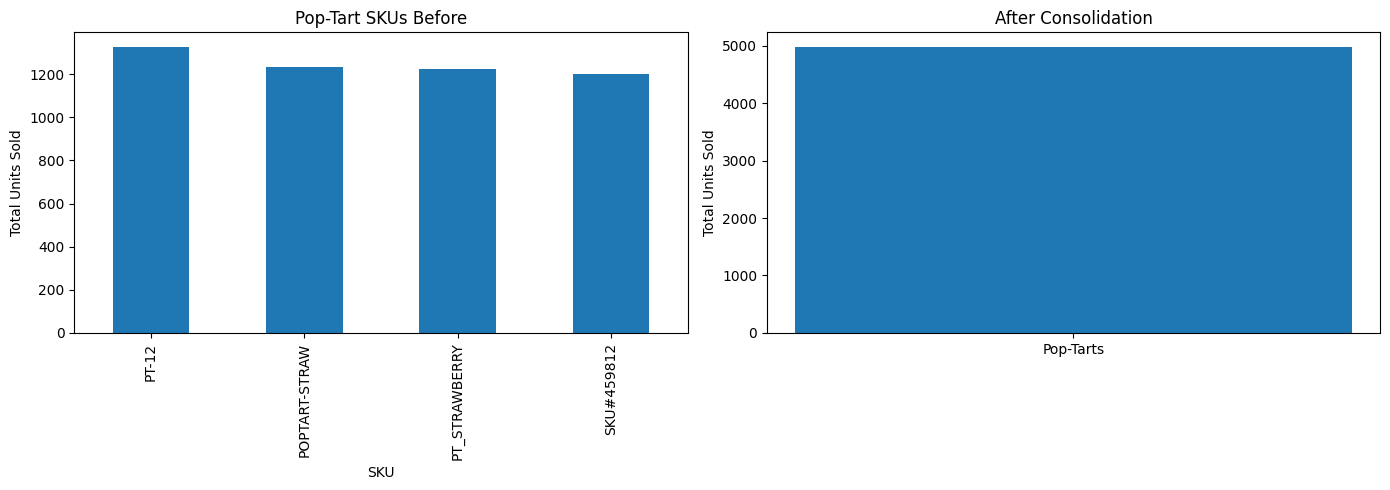

In [24]:
# Before and after bar chart to show SKU consolidation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sku_totals.plot(
    kind='bar',
    ax=axes[0],
    title='Pop-Tart SKUs Before')

axes[0].set_xlabel('SKU')
axes[0].set_ylabel('Total Units Sold')

axes[1].bar(
    ['Pop-Tarts'],
    [total_units])

axes[1].set_title(
    'After Consolidation')
axes[1].set_ylabel('Total Units Sold')

plt.tight_layout()
plt.show()


**Q2 answer:** Interestingly, breakfast items experienced the greatest demand surge with average daily unit sales increading 3.41 times from the baseline

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [25]:
# TODO
# code from q3 in group notebook
BASE = "https://archive-api.open-meteo.com/v1/archive"

# Aggregate cleaned transactions to daily store sales
sales = transactions_clean.copy()
sales['date'] = pd.to_datetime(
    sales['timestamp']
).dt.normalize()

daily_sales = (
    sales.dropna(subset=['date'])
    .groupby(['store_id', 'date'], as_index=False)
    .agg(
        daily_units=('quantity', 'sum'),
        daily_orders=('quantity', 'size')
    )
)

# Validate weather data
assert not weather_clean.empty
assert not weather_clean.duplicated(
    ['store_id', 'date']
).any()

# Join weather and sales
rows_before = len(daily_sales)

sales_weather = daily_sales.merge(
    weather_clean,
    on=['store_id', 'date'],
    how='left',
    validate='many_to_one',
    indicator=True
)

rows_after = len(sales_weather)
q3_join_rows_preserved = rows_before == rows_after

unmatched = (sales_weather['_merge'] != 'both').sum()

print("Rows before join:", rows_before)
print("Rows after join:", rows_after)
print("Rows preserved:", q3_join_rows_preserved)
print("Unmatched rows:", unmatched)

# Source validation
print("\nWeather data sources:")
print(weather_clean['source'].value_counts())

weather_vars = ['precip_mm', 'wind_max', 'pressure_mean']

# Complete observations for all three indicators
complete = sales_weather.dropna(
    subset=['daily_units'] + weather_vars
)

q3_days_in_correlation = complete['date'].nunique()

print("\nDistinct days in correlation:",
      q3_days_in_correlation)

# Correlation analysis
correlations = complete[
    ['daily_units'] + weather_vars
].corr()

print("\nCorrelations:")
display(correlations.round(3))

assert q3_join_rows_preserved
assert unmatched == 0, "Some sales rows have no weather match"


Rows before join: 360
Rows after join: 360
Rows preserved: True
Unmatched rows: 0

Weather data sources:
source
open-meteo    360
Name: count, dtype: int64

Distinct days in correlation: 30

Correlations:


,daily_units,precip_mm,wind_max,pressure_mean
daily_units,1.000,-0.169,0.191,-0.260
precip_mm,-0.169,1.000,0.273,-0.061
wind_max,0.191,0.273,1.000,-0.672
pressure_mean,-0.260,-0.061,-0.672,1.000


**Q3 answer, with its caveat:** Our weather join is successful, perseving all rows, however the correlations aren't particularly strong. The strongest relationships are between precipiatation and pressure, and wind and pressure. None of the weather conditions are correlated strongly with daily unit sales, which surprised our group.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Q4 has been completed, but still needs to be reviewed.

**Q5 (signal or artifact):** This question has not yet been started, but we are planning to work on it as a group when we meet on Tuesday

### Self-check

In [26]:

progress = {
    'q1_multiple': float(top_multiple),
    'q1_baseline_window': 'September 12–18, 2024',
    'q2_canonical_products': canonical_products,
    'q3_join_rows_preserved': bool(q3_join_rows_preserved),
    'q3_days_in_correlation': int(q3_days_in_correlation),
    'charts_with_message_titles': 3,
    'notebook_runs_clean': False,
    'repo_pushed': False
}

for label, value in progress.items():
    filled = not (
        value is None or value is False
        or (isinstance(value, str) and value.startswith('TODO'))
    )
    print('PASS' if filled else 'FAIL', '-', label, '=', value)

print()
print('ready for presentations:', all(
    not (
        v is None or v is False
        or (isinstance(v, str) and v.startswith('TODO'))
    )
    for v in progress.values()
))


PASS - q1_multiple = 3.4111543450064854
PASS - q1_baseline_window = September 12–18, 2024
PASS - q2_canonical_products = 1
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
FAIL - notebook_runs_clean = False
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

a) The finding that surprised us the most was the number of Pop-Tarts units sold, we had to make sure that we were accidentally misconsolidating data when we got that a total of 4985 units were sold.

b) The number that we are least confident in is the correlation between weather conditions and daily sales. We were expecting to see moderate to strong correlations between sales and weather conditions, and instead saw very weak correlations. It is of worth to investigate our time stamping and seleted observation period to make sure we aren't missing meaningful data.